In [1]:

import numpy as np
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X, y = make_moons(n_samples=300, noise=0.25, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = MLPClassifier(hidden_layer_sizes=(100, 100),
                      max_iter=2000,
                      alpha=0.00001,
                      random_state=42)

model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)
print("Training Error:", 1 - train_acc)
print("Testing Error:", 1 - test_acc)

if train_acc - test_acc > 0.1:
    print("Overfitting detected.")
    print("Use regularization, dropout or more training data.")
else:
    print("No significant overfitting detected.")


Training Accuracy: 0.9142857142857143
Testing Accuracy: 0.9333333333333333
Training Error: 0.08571428571428574
Testing Error: 0.06666666666666665
No significant overfitting detected.


In [2]:

import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

np.random.seed(42)

X = np.linspace(1, 10, 100).reshape(-1, 1)
y = 3 * X.ravel()**2 + 2 * X.ravel() + np.random.normal(0, 10, 100)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for degree in [1, 2, 5, 10]:
    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    train_error = mean_squared_error(y_train, train_pred)
    test_error = mean_squared_error(y_test, test_pred)

    print("\nPolynomial Degree:", degree)
    print("Training Error:", train_error)
    print("Testing Error:", test_error)



Polynomial Degree: 1
Training Error: 460.9671528515455
Testing Error: 381.67468678196536

Polynomial Degree: 2
Training Error: 86.02578316535048
Testing Error: 61.96330450394976

Polynomial Degree: 5
Training Error: 79.71842090201622
Testing Error: 64.91260437973094

Polynomial Degree: 10
Training Error: 74.93059403433215
Testing Error: 81.72910875724554


In [3]:

import numpy as np
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression

X, y = make_regression(n_samples=200, n_features=5,
                       noise=20, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

l1_model = Lasso(alpha=1.0)
l2_model = Ridge(alpha=1.0)

l1_model.fit(X_train, y_train)
l2_model.fit(X_train, y_train)

l1_pred = l1_model.predict(X_test)
l2_pred = l2_model.predict(X_test)

print("L1 Regularization (Lasso)")
print("Coefficients:", l1_model.coef_)
print("MSE:", mean_squared_error(y_test, l1_pred))

print("\nL2 Regularization (Ridge)")
print("Coefficients:", l2_model.coef_)
print("MSE:", mean_squared_error(y_test, l2_pred))


L1 Regularization (Lasso)
Coefficients: [ 1.76432628 10.57094657 65.26815849 18.00227345 67.95307246]
MSE: 335.6122415807772

L2 Regularization (Ridge)
Coefficients: [ 2.54359195 11.49793991 65.70527341 18.99987113 68.63134852]
MSE: 337.22775050749203



Learning Rate: 0.001
Final Weight: 1.3423834490294386
Final Loss: 4.973480799694074

Learning Rate: 0.01
Final Weight: 1.9999919506626314
Final Loss: 1.1714499553393864e-09

Learning Rate: 0.1
Final Weight: -18198.8763000044
Final Loss: 2530549221.5060277

Learning Rate: 0.5
Final Weight: -1.9999999999999997e+50
Final Loss: 4.4e+99


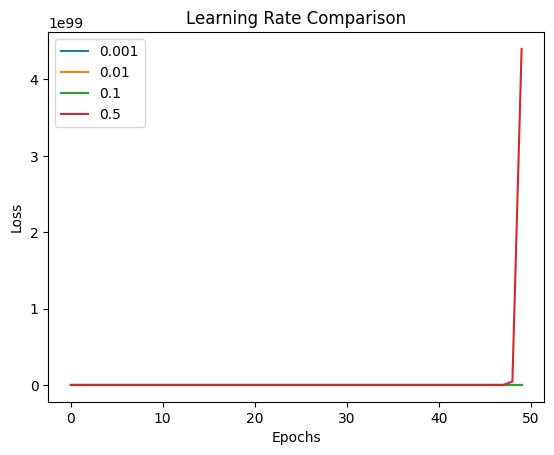

In [4]:

import numpy as np
import matplotlib.pyplot as plt

X = np.array([1, 2, 3, 4, 5], dtype=float)
y = 2 * X

learning_rates = [0.001, 0.01, 0.1, 0.5]
epochs = 50

for lr in learning_rates:
    w = 0.0
    losses = []

    for i in range(epochs):
        prediction = w * X
        loss = np.mean((prediction - y) ** 2)
        gradient = np.mean(2 * (prediction - y) * X)

        w = w - lr * gradient
        losses.append(loss)

    print("\nLearning Rate:", lr)
    print("Final Weight:", w)
    print("Final Loss:", losses[-1])

    plt.plot(losses, label=str(lr))

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.show()


In [5]:

import numpy as np

a = np.float32(0.1)
b = np.float32(0.2)
c = np.float32(0.3)

result1 = a + b

x = np.float64(0.1)
y = np.float64(0.2)
z = np.float64(0.3)

result2 = x + y

print("Float32 Result:", result1)
print("Float32 Expected:", c)
print("Float32 Difference:", abs(result1 - c))

print("\nFloat64 Result:", result2)
print("Float64 Expected:", z)
print("Float64 Difference:", abs(result2 - z))

print("\nFloat32 Precision:", np.finfo(np.float32).eps)
print("Float64 Precision:", np.finfo(np.float64).eps)


Float32 Result: 0.3
Float32 Expected: 0.3
Float32 Difference: 0.0

Float64 Result: 0.30000000000000004
Float64 Expected: 0.3
Float64 Difference: 5.551115123125783e-17

Float32 Precision: 1.1920929e-07
Float64 Precision: 2.220446049250313e-16


In [6]:

import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(random_state=42)

params = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 10, None]
}

grid = GridSearchCV(model, params, cv=3)
grid.fit(X_train, y_train)

print("Grid Search Best Parameters:", grid.best_params_)
print("Grid Search Accuracy:", accuracy_score(y_test, grid.predict(X_test)))

random = RandomizedSearchCV(
    model, params, n_iter=5, cv=3, random_state=42
)
random.fit(X_train, y_train)

print("\nRandom Search Best Parameters:", random.best_params_)
print("Random Search Accuracy:", accuracy_score(y_test, random.predict(X_test)))

# Bayesian Optimization using Gaussian Process
def objective(x):
    n = int(round(x[0]))
    depth = int(round(x[1]))

    m = RandomForestClassifier(
        n_estimators=n, max_depth=depth, random_state=42
    )
    m.fit(X_train, y_train)

    return accuracy_score(y_test, m.predict(X_test))

observations = np.array([[50, 3], [100, 5], [150, 10]], dtype=float)
scores = np.array([objective(x) for x in observations])

for i in range(5):
    gp = GaussianProcessRegressor(
        kernel=Matern(nu=2.5), normalize_y=True,
        random_state=42, n_restarts_optimizer=2
    )
    gp.fit(observations, scores)

    candidates = np.array([
        [n, d] for n in [50, 75, 100, 125, 150, 175, 200]
        for d in [2, 3, 5, 7, 10, 15]
    ], dtype=float)

    mean, std = gp.predict(candidates, return_std=True)
    acquisition = mean + 1.96 * std

    next_point = candidates[np.argmax(acquisition)]

    observations = np.vstack([observations, next_point])
    scores = np.append(scores, objective(next_point))

best = np.argmax(scores)

print("\nBayesian Optimization Best Parameters:")
print("n_estimators:", int(observations[best, 0]))
print("max_depth:", int(observations[best, 1]))
print("Accuracy:", scores[best])


Grid Search Best Parameters: {'max_depth': 10, 'n_estimators': 50}
Grid Search Accuracy: 0.9649122807017544

Random Search Best Parameters: {'n_estimators': 50, 'max_depth': None}
Random Search Accuracy: 0.9649122807017544


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(



Bayesian Optimization Best Parameters:
n_estimators: 50
max_depth: 3
Accuracy: 0.9649122807017544


In [7]:

import numpy as np

states = 4
actions = 2

Q = np.zeros((states, actions))

learning_rate = 0.1
discount = 0.9
epsilon = 0.2
episodes = 1000

# Traffic congestion levels
rewards = np.array([
    [10, -5],
    [8, -3],
    [-5, 10],
    [-3, 8]
])

for episode in range(episodes):
    state = np.random.randint(states)

    for step in range(20):
        if np.random.random() < epsilon:
            action = np.random.randint(actions)
        else:
            action = np.argmax(Q[state])

        reward = rewards[state, action]

        next_state = np.random.randint(states)

        Q[state, action] = Q[state, action] + learning_rate * (
            reward + discount * np.max(Q[next_state]) - Q[state, action]
        )

        state = next_state

print("Learned Q-Table:")
print(Q)

print("\nOptimal Traffic Signal Actions:")

for state in range(states):
    action = np.argmax(Q[state])

    if action == 0:
        print("State", state, ": Green Signal for Road A")
    else:
        print("State", state, ": Green Signal for Road B")


Learned Q-Table:
[[90.66970745 75.81592557]
 [88.5325531  77.83050745]
 [75.57369887 90.82859051]
 [77.41562807 89.1558086 ]]

Optimal Traffic Signal Actions:
State 0 : Green Signal for Road A
State 1 : Green Signal for Road A
State 2 : Green Signal for Road B
State 3 : Green Signal for Road B


In [8]:

import numpy as np

X = np.array([
    [20, 30],
    [30, 40],
    [60, 70],
    [80, 90]
], dtype=float)

y = np.array([0, 0, 1, 1])

X = X / 100

weights = np.zeros(2)
bias = 0
learning_rate = 0.1

for epoch in range(100):
    for i in range(len(X)):
        z = np.dot(X[i], weights) + bias
        prediction = 1 if z >= 0 else 0

        error = y[i] - prediction

        weights = weights + learning_rate * error * X[i]
        bias = bias + learning_rate * error

print("Trained Weights:", weights)
print("Trained Bias:", bias)

print("\nPredictions:")

for sample in X:
    z = np.dot(sample, weights) + bias
    prediction = 1 if z >= 0 else 0

    if prediction == 1:
        print("Eligible")
    else:
        print("Not Eligible")


Trained Weights: [0.1  0.09]
Trained Bias: -0.1

Predictions:
Not Eligible
Not Eligible
Eligible
Eligible


In [9]:

import numpy as np

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([[0], [1], [1], [0]])

np.random.seed(42)

W1 = np.random.randn(2, 4)
b1 = np.zeros((1, 4))

W2 = np.random.randn(4, 1)
b2 = np.zeros((1, 1))

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

learning_rate = 1
epochs = 20000

for i in range(epochs):
    hidden = sigmoid(np.dot(X, W1) + b1)
    output = sigmoid(np.dot(hidden, W2) + b2)

    error = output - y

    d_output = error * output * (1 - output)
    d_hidden = np.dot(d_output, W2.T) * hidden * (1 - hidden)

    W2 -= learning_rate * np.dot(hidden.T, d_output)
    b2 -= learning_rate * np.sum(d_output, axis=0, keepdims=True)

    W1 -= learning_rate * np.dot(X.T, d_hidden)
    b1 -= learning_rate * np.sum(d_hidden, axis=0, keepdims=True)

print("XOR Predictions:")
print(np.round(output, 3))

print("\nFinal Classification:")
print((output >= 0.5).astype(int))


XOR Predictions:
[[0.004]
 [0.995]
 [0.993]
 [0.007]]

Final Classification:
[[0]
 [1]
 [1]
 [0]]


In [10]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = MLPClassifier(
    hidden_layer_sizes=(10, 8),
    activation='relu',
    max_iter=2000,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual Values:")
print(y_test)

print("\nPredicted Values:")
print(predictions)

print("\nAccuracy:", accuracy_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions,
                            target_names=iris.target_names))


Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



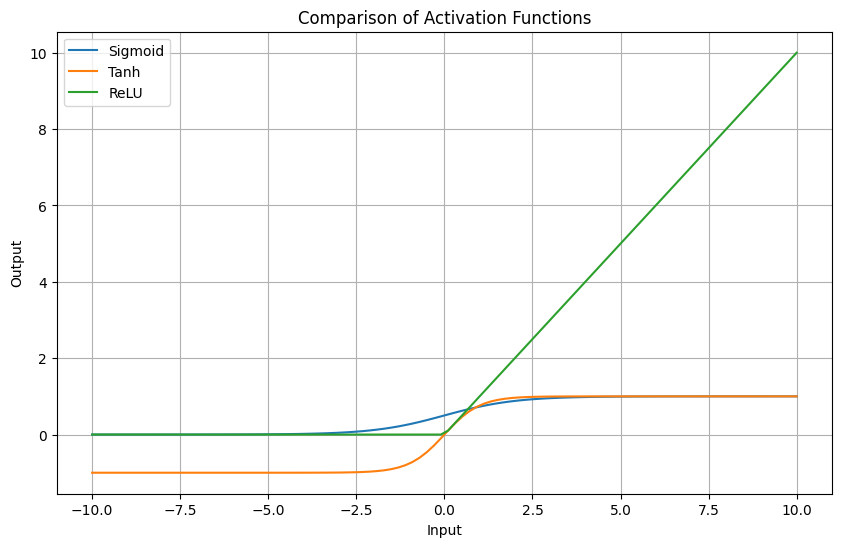

Sigmoid Range: 0 to 1
Tanh Range: -1 to 1
ReLU Range: 0 to infinity


In [11]:

import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.figure(figsize=(10, 6))

plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, relu, label="ReLU")

plt.title("Comparison of Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid()

plt.show()

print("Sigmoid Range: 0 to 1")
print("Tanh Range: -1 to 1")
print("ReLU Range: 0 to infinity")


In [12]:

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X, y = make_classification(
    n_samples=500,
    n_features=10,
    n_informative=8,
    n_redundant=0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

activations = ['relu', 'logistic', 'tanh']

for activation in activations:
    model = MLPClassifier(
        hidden_layer_sizes=(20, 10),
        activation=activation,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    print("\nActivation Function:", activation)
    print("Accuracy:", accuracy)
    print("Training Iterations:", model.n_iter_)
    print("Final Loss:", model.loss_)



Activation Function: relu
Accuracy: 0.86
Training Iterations: 679
Final Loss: 0.021042387201177685


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(



Activation Function: logistic
Accuracy: 0.85
Training Iterations: 1000
Final Loss: 0.10328639343122387

Activation Function: tanh
Accuracy: 0.86
Training Iterations: 656
Final Loss: 0.014548426601794753


In [13]:

import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

X = np.array([[0.5, 0.8]])

W1 = np.array([
    [0.2, 0.4],
    [0.3, 0.5]
])

b1 = np.array([[0.1, 0.1]])

W2 = np.array([[0.6], [0.7]])
b2 = np.array([[0.2]])

hidden_input = np.dot(X, W1) + b1
hidden_output = sigmoid(hidden_input)

output_input = np.dot(hidden_output, W2) + b2
final_output = sigmoid(output_input)

print("Input:", X)
print("Hidden Layer Input:", hidden_input)
print("Hidden Layer Output:", hidden_output)
print("Output Layer Input:", output_input)
print("Final Output:", final_output)


Input: [[0.5 0.8]]
Hidden Layer Input: [[0.44 0.7 ]]
Hidden Layer Output: [[0.60825903 0.66818777]]
Output Layer Input: [[1.03268686]]
Final Output: [[0.73743647]]


In [14]:

import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

X = np.array([[0.5, 0.8]])
y = np.array([[1]])

W1 = np.array([[0.2, 0.4],
               [0.3, 0.5]])

W2 = np.array([[0.6], [0.7]])

b1 = np.array([[0.1, 0.1]])
b2 = np.array([[0.2]])

learning_rate = 0.5

# Forward Propagation
hidden = sigmoid(np.dot(X, W1) + b1)
output = sigmoid(np.dot(hidden, W2) + b2)

loss = 0.5 * np.sum((y - output) ** 2)

print("Initial Output:", output)
print("Initial Loss:", loss)

# Backpropagation
output_error = (output - y) * output * (1 - output)

hidden_error = np.dot(output_error, W2.T) * hidden * (1 - hidden)

# Weight and Bias Updates
W2 -= learning_rate * np.dot(hidden.T, output_error)
b2 -= learning_rate * output_error

W1 -= learning_rate * np.dot(X.T, hidden_error)
b1 -= learning_rate * hidden_error

# Forward Propagation After Update
hidden = sigmoid(np.dot(X, W1) + b1)
output = sigmoid(np.dot(hidden, W2) + b2)

new_loss = 0.5 * np.sum((y - output) ** 2)

print("\nUpdated Output:", output)
print("Updated Loss:", new_loss)
print("Updated W1:")
print(W1)
print("Updated W2:")
print(W2)


Initial Output: [[0.73743647]]
Initial Loss: 0.034469804220942556

Updated Output: [[0.74669266]]
Updated Loss: 0.032082304117394274
Updated W1:
[[0.20181707 0.40197252]
 [0.30290732 0.50315604]]
Updated W2:
[[0.61546151]
 [0.71698486]]


In [15]:

import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X = np.array([
    [1000, 2],
    [1200, 2],
    [1500, 3],
    [1800, 3],
    [2000, 4],
    [2200, 4],
    [2500, 4],
    [2800, 5],
    [3000, 5],
    [3500, 5]
])

y = np.array([25, 30, 40, 48, 55, 60, 70, 78, 85, 100])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = MLPRegressor(
    hidden_layer_sizes=(20, 10),
    activation='relu',
    solver='adam',
    max_iter=5000,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual House Prices:", y_test)
print("Predicted House Prices:", predictions)

print("Mean Squared Error:",
      mean_squared_error(y_test, predictions))

print("R2 Score:", r2_score(y_test, predictions))


Actual House Prices: [85 30]
Predicted House Prices: [84.7653977  31.45797002]
Mean Squared Error: 1.090357415335016
R2 Score: 0.9985582050706314


In [16]:

import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

X = np.array([
    [100, 1],
    [200, 2],
    [150, 1],
    [5000, 9],
    [6000, 10],
    [7000, 8],
    [120, 2],
    [8000, 10],
    [180, 1],
    [9000, 9]
])

y = np.array([0, 0, 0, 1, 1, 1, 0, 1, 0, 1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = MLPClassifier(
    hidden_layer_sizes=(10, 5),
    activation='relu',
    solver='adam',
    max_iter=3000,
    random_state=42
)

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

epsilon = 1e-15
probabilities = np.clip(probabilities, epsilon, 1 - epsilon)

bce = -np.mean(
    y_test * np.log(probabilities) +
    (1 - y_test) * np.log(1 - probabilities)
)

print("Actual Values:", y_test)
print("Predicted Values:", predictions)
print("Fraud Probabilities:", probabilities)

print("\nBinary Cross-Entropy Loss:", bce)
print("Accuracy:", accuracy_score(y_test, predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, predictions, zero_division=0
))


Actual Values: [0 0 1]
Predicted Values: [0 0 0]
Fraud Probabilities: [1.40941876e-01 1.67472076e-01 1.00000000e-15]

Binary Cross-Entropy Loss: 11.624661201663075
Accuracy: 0.6666666666666666

Confusion Matrix:
[[2 0]
 [1 0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3

